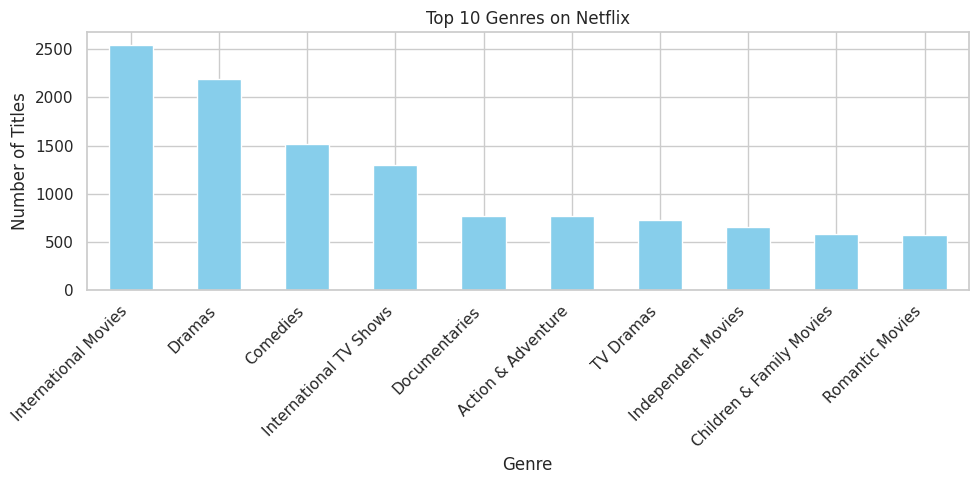

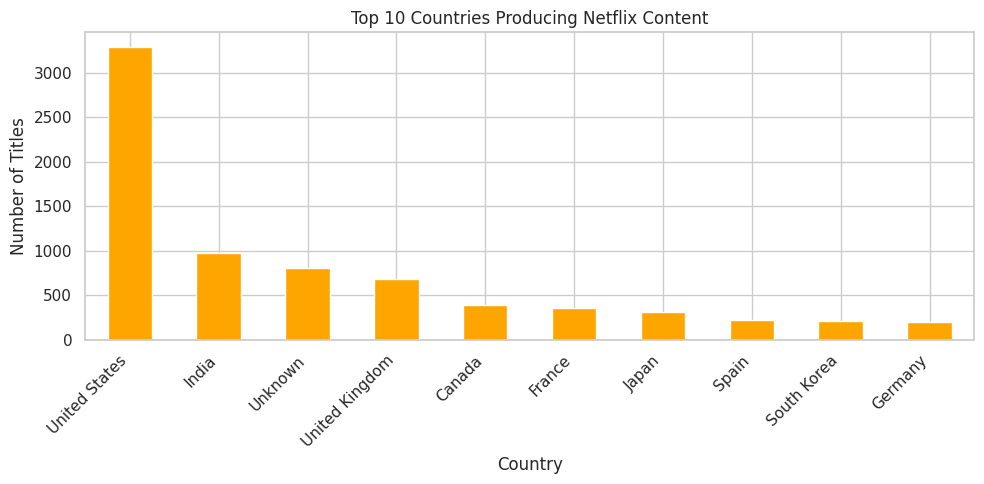

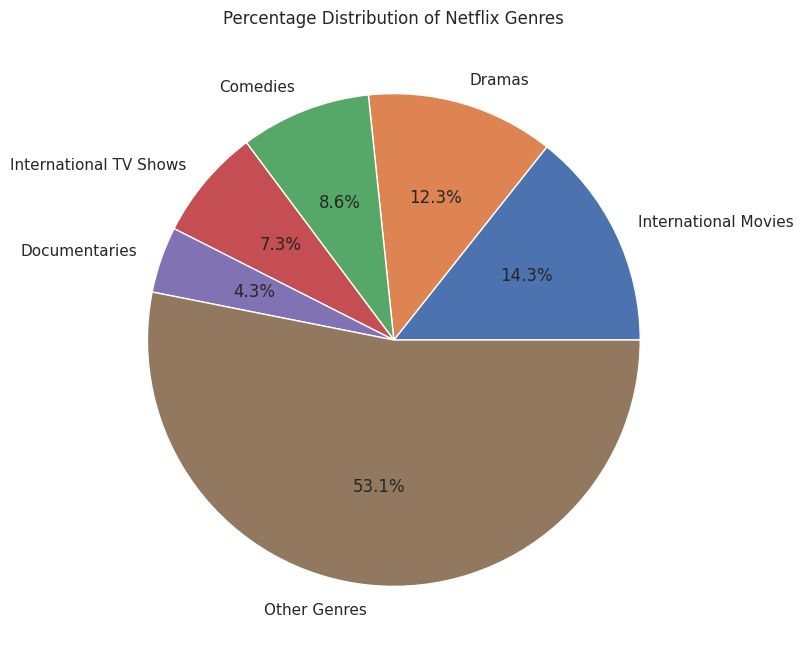

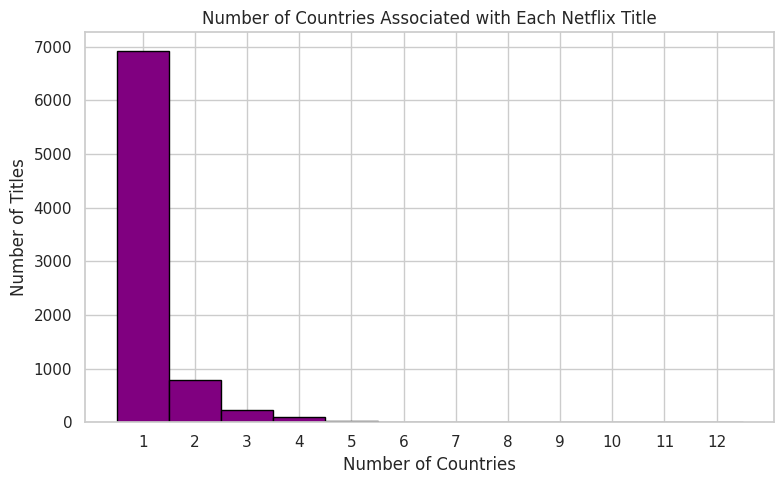

Most common genre: International Movies
Country with the most titles: United States
Most common genre count: 2545
Country with the most titles count: 3291


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("netflix_cleaned.csv")


# 1. Top 10 Genres - Bar Chart

genres = df["listed_in"].dropna().str.split(",").explode().str.strip()
top_genres = genres.value_counts().head(10)

top_genres.plot(kind="bar", color="skyblue", figsize=(10, 5))
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 2. Top 10 Countries - Bar Chart

countries = df["country"].dropna().str.split(",").explode().str.strip()
countries = countries[countries != ""]
top_countries = countries.value_counts().head(10)

top_countries.plot(kind="bar", color="orange", figsize=(10, 5))
plt.title("Top 10 Countries Producing Netflix Content")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 3. Genre Distribution - Pie Chart

genre_counts = genres.value_counts()
top_5_genres = genre_counts.head(5)
other_genres = genre_counts.iloc[5:].sum()

pie_data = pd.concat([
    top_5_genres,
    pd.Series({"Other Genres": other_genres})
])

pie_data.plot(kind="pie", autopct="%1.1f%%", figsize=(8, 8))
plt.title("Percentage Distribution of Netflix Genres")
plt.ylabel("")
plt.show()


# 4. Number of Countries per Title - Histogram

country_per_title = df["country"].dropna().apply(
    lambda x: len([c for c in x.split(",") if c.strip()])
)

plt.figure(figsize=(8, 5))
plt.hist(country_per_title, bins=range(1, country_per_title.max() + 2),
         color="purple", edgecolor="black", align="left")

plt.title("Number of Countries Associated with Each Netflix Title")
plt.xlabel("Number of Countries")
plt.ylabel("Number of Titles")
plt.xticks(range(1, country_per_title.max() + 1))
plt.tight_layout()
plt.show()


# Display main findings
print("Most common genre:", top_genres.index[0])
print("Country with the most titles:", top_countries.index[0])
print("Most common genre count:", top_genres.iloc[0])
print("Country with the most titles count:", top_countries.iloc[0])